# Red neuronal multicapa (MLP) con MNIST

**Materia:** Inteligencia Artificial  
**Docente:** José Mario Ríos Félix  
**Horario:** 6:00 a 7:00 p. m.  
**Alumna:** Kitzia Marisol Crespo Hernández  
**Número de control:** C23171148

## Descripción

Esta notebook implementa y entrena una red neuronal multicapa (MLP) utilizando el dataset MNIST para clasificar dígitos escritos a mano del 0 al 9.

El proceso consiste en preparar las imágenes, crear y entrenar la red neuronal, evaluar su precisión y guardar el modelo en "mlp_model.keras".

Asimismo, se desarrolla el programa **reconocer-digito.py**, que permite dibujar dígitos en tiempo real y obtener una predicción del número dibujado mediante el modelo previamente entrenado, sin necesidad de repetir el entrenamiento.

## 1. Cargar los datos

MNIST viene incluido en Keras. Son 70,000 imágenes de dígitos escritos a mano,
60,000 para entrenar y 10,000 para probar, cada una de 28 por 28 píxeles.

In [19]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense

# Carga del conjunto de datos MNIST
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

In [20]:
x_train.shape[0]

60000

In [21]:
x_test.shape[0]

10000

## 2. Preprocesamiento

Se normalizan los valores de los píxeles dividiéndolos entre 255, para convertir su rango de 0 a 255 en uno de 0 a 1, ya que esto facilita el entrenamiento de la red neuronal al mantener los datos en una escala uniforme.

In [22]:
gray_scale = 255

x_train = x_train.astype('float32') / gray_scale
x_test = x_test.astype('float32') / gray_scale

print("Feature matrix (x_train):", x_train.shape)
print("Target matrix (y_train):", y_train.shape)
print("Feature matrix (x_test):", x_test.shape)
print("Target matrix (y_test):", y_test.shape)

Feature matrix (x_train): (60000, 28, 28)
Target matrix (y_train): (60000,)
Feature matrix (x_test): (10000, 28, 28)
Target matrix (y_test): (10000,)


**x_train** guarda las imágenes y **y_train** la etiqueta de cada una, que es el
dígito correcto. Abajo se ve una fila de píxeles de la primera imagen y las diez
primeras etiquetas, que van del 0 al 9.

In [23]:
x_train[0][15]

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.1764706 ,
       0.7294118 , 0.99215686, 0.99215686, 0.5882353 , 0.10588235,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        ], dtype=float32)

In [24]:
y_train[0:10]

array([5, 0, 4, 1, 9, 2, 1, 3, 1, 4], dtype=uint8)

Las primeras 100 imágenes del conjunto de entrenamiento.

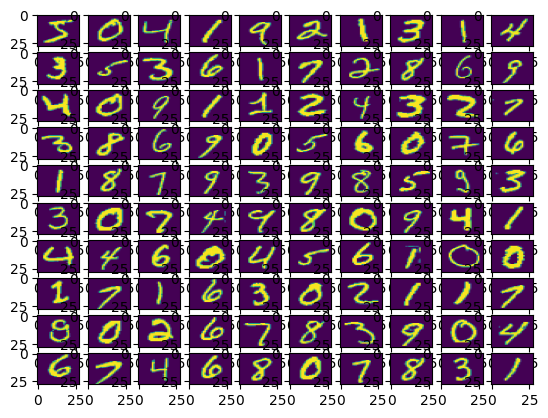

In [25]:
fig, ax = plt.subplots(10, 10)
k = 0
for i in range(10):
    for j in range(10):
        ax[i][j].imshow(x_train[k].reshape(28, 28), aspect='auto')
        k += 1
plt.show()

## 3. Construcción de la red neuronal

*Flatten* transforma cada imagen de 28 × 28 píxeles en 784 valores de entrada, seguidos de dos capas densas de 256 y 128 neuronas con activación sigmoide y una capa de salida de 10 neuronas con **softmax**, que genera probabilidades para los dígitos del 0 al 9.

In [26]:
model = Sequential([
    Input(shape=(28, 28)),             # La entrada, una imagen de 28 por 28
    Flatten(),                         # Convierte la imagen 2D en una lista plana de 784 valores
    Dense(256, activation='sigmoid'),  # Primera capa oculta con 256 neuronas
    Dense(128, activation='sigmoid'),  # Segunda capa oculta con 128 neuronas
    Dense(10, activation='softmax'),   # Capa de salida, probabilidad de cada dígito del 0 al 9
])

En clase se utilizó **Flatten(input_shape=(28, 28))**, pero la versión actual de Keras recomienda definir la entrada mediante una capa **Input** independiente. Este cambio no modifica la arquitectura ni el funcionamiento del modelo.

In [27]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Compilación del modelo

- **Adam:** Optimizador que ajusta los pesos y bias de la red neuronal para reducir el error.
- **Sparse Categorical Crossentropy:** Función de pérdida utilizada en clasificación multiclase cuando las etiquetas son números enteros, como en MNIST.
- **Accuracy:** Métrica que mide el porcentaje de predicciones correctas.

In [28]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

## 5. Entrenamiento del modelo

- **epochs:** Número de veces que la red recorre los datos de entrenamiento.
- **batch_size:** Cantidad de imágenes procesadas por lote durante el entrenamiento.
- **validation_split:** Reserva el 20 % de las 60,000 imágenes para validar el modelo, sin utilizar los datos de prueba (`x_test`).

Con esta configuración, se entrenan 48,000 imágenes en 24 lotes de 2,000 por época.

In [29]:
mod = model.fit(x_train, y_train, epochs=10,
          batch_size=2000,
          validation_split=0.2)

print(mod)

Epoch 1/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.3978 - loss: 2.0919 - val_accuracy: 0.6747 - val_loss: 1.7382
Epoch 2/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.7232 - loss: 1.4074 - val_accuracy: 0.7861 - val_loss: 1.0640
Epoch 3/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.8129 - loss: 0.8917 - val_accuracy: 0.8599 - val_loss: 0.6994
Epoch 4/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.8604 - loss: 0.6282 - val_accuracy: 0.8845 - val_loss: 0.5168
Epoch 5/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.8831 - loss: 0.4905 - val_accuracy: 0.8970 - val_loss: 0.4213
Epoch 6/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.8957 - loss: 0.4133 - val_accuracy: 0.9054 - val_loss: 0.3653
Epoch 7/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9034 - loss: 0.3665 - val_accuracy: 0.9118 - val_loss: 0.3291
Epoch 8/10
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9094 - loss: 0.3332 - val_accuracy: 0.9182 - v

## 6. Evaluar con los datos de prueba

Ahora se mide con las 10,000 imágenes que la red nunca vio. Este es el número
importante, dado que dice qué tan bien puede generalizar con datos nuevos.

In [30]:
results = model.evaluate(x_test, y_test, verbose=0)
print('Test loss, Test accuracy:', results)

Test loss, Test accuracy: [0.2747311294078827, 0.9223999977111816]


## 7. Ver cómo avanzó el entrenamiento

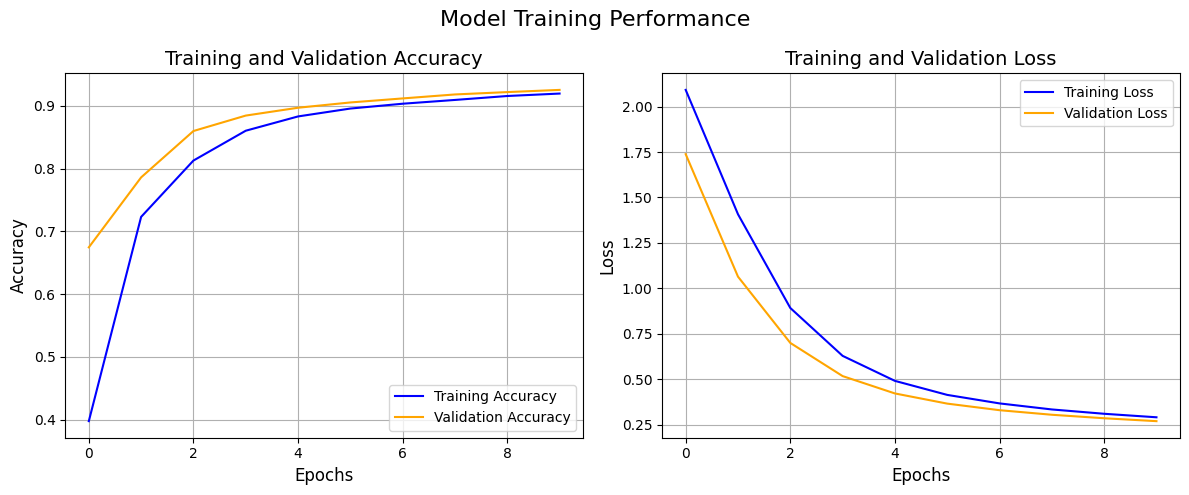

In [31]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(mod.history['accuracy'], label='Training Accuracy', color='blue')
plt.plot(mod.history['val_accuracy'],
         label='Validation Accuracy', color='orange')
plt.title('Training and Validation Accuracy', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(mod.history['loss'], label='Training Loss', color='blue')
plt.plot(mod.history['val_loss'], label='Validation Loss', color='orange')
plt.title('Training and Validation Loss', fontsize=14)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend()
plt.grid(True)

plt.suptitle("Model Training Performance", fontsize=16)
plt.tight_layout()
plt.show()

Las curvas muestran que la precisión aumenta y la pérdida disminuye, por lo que se decidió entrenar el modelo durante más épocas.

## 8. Entrenar más épocas

Al ejecutar nuevamente *fit()* sobre el mismo modelo, el entrenamiento continúa desde donde terminó, sin comenzar desde cero, por lo que se acumulan 25 épocas en total, es decir, las 10 anteriores más las 15 adicionales.

In [32]:
history = model.fit(x_train, y_train, epochs=15,
          batch_size=2000,
          validation_split=0.2)

Epoch 1/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.9235 - loss: 0.2744 - val_accuracy: 0.9262 - val_loss: 0.2569
Epoch 2/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.9265 - loss: 0.2604 - val_accuracy: 0.9301 - val_loss: 0.2451
Epoch 3/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9302 - loss: 0.2480 - val_accuracy: 0.9335 - val_loss: 0.2349
Epoch 4/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9325 - loss: 0.2368 - val_accuracy: 0.9352 - val_loss: 0.2266
Epoch 5/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.9352 - loss: 0.2264 - val_accuracy: 0.9376 - val_loss: 0.2179
Epoch 6/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9380 - loss: 0.2163 - val_accuracy: 0.9410 - val_loss: 0.2090
Epoch 7/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9402 - loss: 0.2073 - val_accuracy: 0.9430 - val_loss: 0.2036
Epoch 8/15
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9425 - loss: 0.1994 - val_accuracy: 0.9443 - v

In [33]:
results = model.evaluate(x_test, y_test, verbose=0)
print('Test loss, Test accuracy:', results)

Test loss, Test accuracy: [0.15695512294769287, 0.9532999992370605]


Con las 25 épocas acumuladas la precisión con los datos de prueba subió de 92.24 % a 95.33 % y la pérdida bajó de 0.2747 a 0.1570.

Aumentar las épocas no siempre mejora el modelo, ya que puede producir sobreajuste (*overfitting*), cuando aprende demasiado los datos de entrenamiento y pierde capacidad para generalizar

## 9. Guardar el modelo entrenado

El archivo **.keras** guarda la arquitectura y los pesos aprendidos, así el programa de predicción carga el modelo directamente sin repetir el entrenamiento con las 60,000 imágenes

In [34]:
model.save("mlp_model.keras")  # Guardar el modelo entrenado para su uso futuro

import os
print("archivo guardado, %.1f MB" % (os.path.getsize("mlp_model.keras") / 1024 / 1024))

archivo guardado, 2.7 MB


## 10. Probar el modelo guardado

Se carga el modelo y se realizan **predicciones** con imágenes de prueba para verificar su funcionamiento, utilizando **predict** para obtener las probabilidades y **argmax** para seleccionar la clase con mayor valor

In [35]:
modelo_cargado = tf.keras.models.load_model("mlp_model.keras")

probabilidades = modelo_cargado.predict(x_test[:10])
predicciones = np.argmax(probabilidades, axis=1)

print("predicciones", predicciones)
print("reales      ", y_test[:10])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step
predicciones [7 2 1 0 4 1 4 9 6 9]
reales       [7 2 1 0 4 1 4 9 5 9]


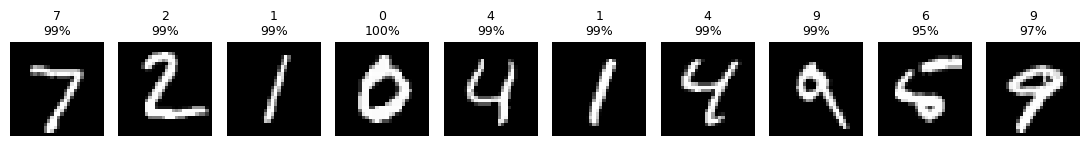

In [36]:
plt.figure(figsize=(11, 3))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    seguridad = probabilidades[i][predicciones[i]] * 100
    plt.title("%d\n%.0f%%" % (predicciones[i], seguridad), fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

## Conclusión

El modelo entrenado se guarda en **mlp_model.keras** y se utiliza en el programa **reconocer-digito.py**, que permite dibujar números en tiempo real, procesarlos y mostrar la predicción del número junto con su probabilidad